<a href="https://colab.research.google.com/github/diddat/Midterm-Project-Econ_3916_Midterm.ipynb/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import os

os.makedirs("figures", exist_ok=True)
os.makedirs("output", exist_ok=True)
os.makedirs("data", exist_ok=True)

In [33]:
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [17]:
SOURCE_URL = "https://api.census.gov/data/2025/acs/acs1"
DOWNLOAD_DATE = "2026-11-03"
FILE_NAME = "data/housing_vacancy_rents_2025.csv"

**Who collected it, for what purpose, what is missing and why?**

The data come from the U.S. Census Bureau's 2025 American Community Survey (ACS) 1-Year Estimates. The Census Bureau collects information about housing, income, employment, and demographic characteristics to help researchers, businesses, and policymakers understand economic conditions.

Each observation represents one U.S. Census place in 2025. The dataset contains median monthly gross rent, median annual household income, unemployment rates, and housing vacancy rates.

The ACS uses survey estimates rather than collecting information from every household. The 1-year estimates generally cover places with populations of at least 65,000, so smaller communities are excluded.

The four variables selected for this analysis had no missing values in my initial download of 672 places. I will verify this again using the final dataset. Although no observations may be missing within the selected sample, the geographic population threshold means the sample does not represent every U.S. city. This is a coverage limitation based on population size, rather than ordinary missing values within the downloaded dataset.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [19]:
# SECTION 1: DATA LOADING
# Project: Does Housing Availability Affect Rental Prices?
# Source: 2025 American Community Survey

import pandas as pd
import numpy as np
import requests
from getpass import getpass
from pathlib import Path

# STEP 1: Enter Census API key
api_key = getpass("Enter your Census API key: ").strip()

# STEP 2: Define the Census variables
variables = {
    "B25064_001E": "median_rent",
    "B19013_001E": "median_income",
    "B23025_003E": "labor_force",
    "B23025_005E": "unemployed",
    "B25002_001E": "housing_units",
    "B25002_003E": "vacant_units"
}

# STEP 3: Download 2025 Census data
params = {
    "get": "NAME," + ",".join(variables.keys()),
    "for": "place:*",
    "in": "state:*",
    "key": api_key
}

response = requests.get(
    SOURCE_URL,
    params=params,
    timeout=120,
    allow_redirects=False
)

if response.status_code != 200:
    raise RuntimeError(
        "Census request failed. HTTP status: "
        + str(response.status_code)
        + "\n" + response.text[:300]
    )

try:
    results = response.json()
except ValueError:
    raise RuntimeError(
        "Census did not return valid JSON. "
        "Check your API key."
    )

# STEP 4: Create the DataFrame
raw = pd.DataFrame(
    results[1:],
    columns=results[0]
)

raw = raw.rename(columns=variables)

# Convert Census estimates into numbers
for col in variables.values():
    raw[col] = pd.to_numeric(
        raw[col], errors="coerce"
    )
    raw.loc[raw[col] < 0, col] = np.nan

# STEP 5: Calculate unemployment rate
raw["unemployment_pct"] = (
    100 * raw["unemployed"] /
    raw["labor_force"].replace(0, np.nan)
)

# STEP 6: Calculate housing vacancy rate
raw["vacancy_pct"] = (
    100 * raw["vacant_units"] /
    raw["housing_units"].replace(0, np.nan)
)

# STEP 7: Create final dataset
df = raw[[
    "NAME",
    "median_rent",
    "vacancy_pct",
    "median_income",
    "unemployment_pct"
]].copy()

# Check for invalid numbers
df.loc[df["median_rent"] <= 0, "median_rent"] = np.nan
df.loc[df["median_income"] <= 0, "median_income"] = np.nan

for col in ["vacancy_pct", "unemployment_pct"]:
    df.loc[~df[col].between(0, 100), col] = np.nan

# STEP 8: Check data availability
print("=== DATASET INFORMATION ===")
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values per column:")
print(df.isna().sum())

print("\nMissing percentage per column:")
print((df.isna().mean() * 100).round(2))

print("\nComplete observations:", len(df.dropna()))

# Stop if unexpectedly many observations are missing
missing_rates = df.isna().mean()

if (missing_rates > 0.05).any():
    raise RuntimeError(
        "WARNING: At least one variable has over "
        "5% missing observations. Investigate before "
        "continuing."
    )

print("\nData quality check passed!")

# STEP 9: Preview the data
display(df.head())

# STEP 10: Save dataset
Path("data").mkdir(parents=True, exist_ok=True)

df.to_csv(FILE_NAME, index=False)

print("\nDataset saved to:", FILE_NAME)


Enter your Census API key: ··········
=== DATASET INFORMATION ===
Rows: 672
Columns: 5

Missing values per column:
NAME                0
median_rent         0
vacancy_pct         0
median_income       0
unemployment_pct    0
dtype: int64

Missing percentage per column:
NAME                0.0
median_rent         0.0
vacancy_pct         0.0
median_income       0.0
unemployment_pct    0.0
dtype: float64

Complete observations: 672

Data quality check passed!


,NAME,median_rent,vacancy_pct,median_income,unemployment_pct
0,"Auburn city, Alabama",1242.0,17.537395,66289.0,6.539844
1,"Birmingham city, Alabama",1188.0,20.521702,46749.0,5.137260
2,"Dothan city, Alabama",1045.0,11.430387,59829.0,4.107469
3,"Hoover city, Alabama",1644.0,8.442531,123096.0,2.705496
4,"Huntsville city, Alabama",1313.0,14.306045,83850.0,6.373621



Dataset saved to: data/housing_vacancy_rents_2025.csv


In [20]:
# Section 1 self-check
UNIT = "U.S. Census place in 2025"
OUTCOME = "median_rent"
MAIN_X = "vacancy_pct"
CONTROLS = [ "median_income",
    "unemployment_pct"]

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 672   Columns: 5   One row is: U.S. Census place in 2025

Missing values per column:
median_rent         0
vacancy_pct         0
median_income       0
unemployment_pct    0

Skew of median_rent: 0.48 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?


1.My main explanatory variable is the housing vacancy rate. I include median household income because cities with higher incomes may have greater housing demand and higher rents, while income may also be related to vacancy. I include unemployment because local economic conditions can influence housing demand, employment opportunities, income, and rental prices. These controls are intended to reduce confounding. They could become bad controls if vacancy rates themselves influence local income or unemployment. The relationship may also suffer from reverse causality because rental prices can affect vacancy rates.

2.All variables describe U.S. Census places in 2025, so they use the same geographic unit and year. Median rent is measured in monthly dollars, median household income in annual dollars, and vacancy and unemployment rates in percentages. These differences in measurement units will be considered when interpreting regression coefficients.

3.My research question does not evaluate a specific policy. Instead, it examines differences in rental prices and housing-market conditions across cities during one year. Therefore, a before-and-after comparison is not required.

**Research Question:** Are higher housing vacancy rates associated with lower median monthly rents across U.S. cities in 2025, after accounting for household income and unemployment?

I chose this question because housing affordability is an important economic concern for individuals and families, particularly those looking to rent in expensive cities. Understanding the relationship between housing vacancy and rental prices can provide insight into how housing-market conditions differ across cities.

My dependent variable is median monthly gross rent. My main explanatory variable is the housing vacancy rate, calculated as the percentage of housing units that are vacant. I also include median household income and the unemployment rate as additional explanatory variables.

I expect cities with higher housing vacancy rates to have lower median rents, holding other economic conditions constant. However, vacancy rates may reflect factors other than housing available to rent, and the relationship could work in both directions.

The analysis uses data from the U.S. Census Bureau's 2025 American Community Survey. Each observation represents one U.S. Census place. The study will use descriptive statistics, visualizations, and multivariate OLS regression to identify associations rather than prove causation.

**Summary Statistics:**

The following table presents the number of observations, mean, standard deviation, minimum, median, and maximum for each economic variable.

**Measurement and missingness.**

The ACS is a rolling sample survey of about 3.5 million addresses a year, run by the Census Bureau to allocate federal funds and describe communities between decennial censuses. It was not designed to study rent-setting, and three measurement decisions shape what my variables can say.

First, *coverage by design*. The Census Bureau publishes 1-year estimates only for places with at least 65,000 residents, because smaller places have too few sampled households for a reliable single-year estimate. My 672 places are therefore the large cities and census-designated places of the U.S., not a sample of all places. This is **unit missingness**, and I label it **MAR (missing at random)**: whether a place appears depends on its population, which the Census Bureau observes and which is not the rent itself. It is not MCAR, because small places are systematically different (lower rents, different vacancy patterns), so my estimate describes large places only and should not be extrapolated to small towns. It is not MNAR, because conditional on population the rule does not depend on a place's rent or vacancy.

Second, *top-coding*. The ACS reports median gross rent of \$3,500 or more as 3,501 and median household income of \$250,000 or more as 250,001; the maximum values in my table are exactly these codes. For the affected places the true value is hidden *because it is high*, which is the defining feature of **MNAR** missingness for those values. Few places are affected (the measurement-check cell below counts them), so I keep them and flag them; the influence check in Section 4 shows whether any of them are among the observations that drive the estimate.

Third, *what "vacancy" means*. My vacancy rate is the share of **all** housing units that are vacant (table B25002). It counts units for rent, but also units for sale, units held for seasonal or recreational use, and units vacant for other reasons such as repair or abandonment. It is therefore a noisy proxy for rental availability, which tends to bias the vacancy coefficient toward zero. All estimates are also survey estimates with sampling error (the ACS publishes margins of error, which I do not use), and gross rent includes utilities as well as contract rent.

Item missingness is zero: none of my four variables has a missing or suppressed value in the 672 places (Census suppression codes, which are negative numbers, would have been converted to missing by my loading cell).

In [21]:
# CHECKPOINT 2: SUMMARY STATISTICS

# Select the economic variables
model_columns = [
    "median_rent",
    "vacancy_pct",
    "median_income",
    "unemployment_pct"
]

# Use observations with complete data
analysis_df = df.dropna(
    subset=model_columns
).copy()

# Calculate summary statistics
summary = analysis_df[model_columns].describe().T

summary = summary[[
    "count", "mean", "std", "min", "50%", "max"
]]

# Rename columns
summary.columns = [
    "N", "Mean", "Std. Dev.",
    "Minimum", "Median", "Maximum"
]

# Rename rows
summary.index = [
    "Median Monthly Gross Rent ($)",
    "Housing Vacancy Rate (%)",
    "Median Household Income ($)",
    "Unemployment Rate (%)"
]

# Display table
print("=== CHECKPOINT 2: SUMMARY STATISTICS ===")
display(summary.round(2))

print("\nTotal observations:", len(df))
print("Complete observations:", len(analysis_df))

# Examine skewness of the dependent variable
print(
    "\nSkewness of median rent:",
    round(analysis_df["median_rent"].skew(), 3)
)

# Save clean dataset
analysis_df.to_csv(
    "data/housing_vacancy_rents_2025_clean.csv",
    index=False
)

# Save summary table
summary.to_csv(
    "data/summary_statistics_2025.csv"
)


=== CHECKPOINT 2: SUMMARY STATISTICS ===


,N,Mean,Std. Dev.,Minimum,Median,Maximum
Median Monthly Gross Rent ($),672.0,1776.87,512.80,482.00,1749.50,3501.00
Housing Vacancy Rate (%),672.0,7.33,4.84,0.00,6.21,43.36
Median Household Income ($),672.0,91499.33,31622.59,19086.00,85435.50,250001.00
Unemployment Rate (%),672.0,5.34,2.29,0.77,5.00,18.87



Total observations: 672
Complete observations: 672

Skewness of median rent: 0.479


 One row is one U.S. Census place with at least 65,000 residents, from the 2025 ACS 1-year estimates (N = 672). Median monthly gross rent is contract rent plus utilities, in dollars per month. Median household income is in dollars per year. The vacancy rate is vacant housing units as a percentage of all housing units, counting all reasons for vacancy. The unemployment rate is unemployed people as a percentage of the civilian labor force. The maximum rent (\$3,501) and maximum income (\$250,001) are ACS top codes, meaning "this value or more". Rates are in percentage points, so a change from 5.0 to 6.0 is one percentage point.

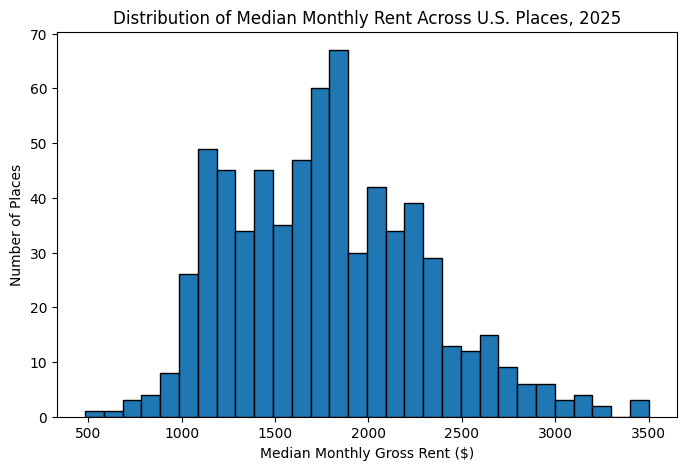

Original rent skewness: 0.479


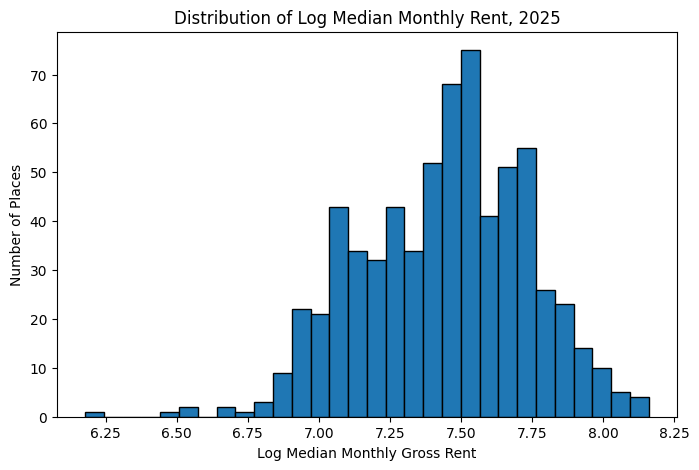

Log rent skewness: -0.303


In [22]:
# Checking whether median rent is skewed

import matplotlib.pyplot as plt
import numpy as np

# Plot the original distribution
plt.figure(figsize=(8, 5))
plt.hist(analysis_df["median_rent"], bins=30, edgecolor="black")
plt.title("Distribution of Median Monthly Rent Across U.S. Places, 2025")
plt.xlabel("Median Monthly Gross Rent ($)")
plt.ylabel("Number of Places")
plt.show()

# Calculate skewness
print("Original rent skewness:",
      round(analysis_df["median_rent"].skew(), 3))

# Create log-transformed rent
analysis_df["log_rent"] = np.log(analysis_df["median_rent"])

# Examine the transformed distribution
plt.figure(figsize=(8, 5))
plt.hist(analysis_df["log_rent"], bins=30, edgecolor="black")
plt.title("Distribution of Log Median Monthly Rent, 2025")
plt.xlabel("Log Median Monthly Gross Rent")
plt.ylabel("Number of Places")
plt.show()

print("Log rent skewness:",
      round(analysis_df["log_rent"].skew(), 3))


In [27]:
print("Raw slope:", B_RAW)
print("R-squared:", main.rsquared)

Raw slope: -38.30827480468396
R-squared: 0.6672878601657299


## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

The two figures below show the outcome on its own and then its relationship with the main explanatory variable. Following Chapter 3, every axis starts at zero so that distances are not exaggerated, no axis is truncated, axis labels give units, gridlines and decoration are kept to a minimum, and the ACS top codes are marked. Each caption is printed by its cell so that every number in it comes from the data.

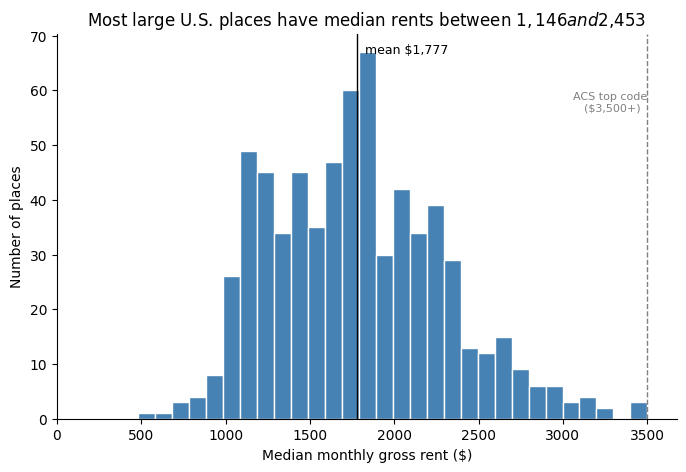

Figure 1. Median rent is only mildly right-skewed (skewness = 0.48; -0.30 after taking logs). Eighty percent of places have median rents between $1,146 and $2,453 a month, with a thin tail of expensive places and 2 places stacked at the ACS top code of $3,501. Because the skew is below the rule-of-thumb threshold of 1, I keep rent in dollars, which makes the coefficients readable as dollars per month.


In [23]:
# Figure 1: the outcome's distribution
rent = analysis_df["median_rent"]
RENT_SKEW = rent.skew()
LOG_RENT_SKEW = np.log(rent).skew()
p10, p90 = rent.quantile([0.10, 0.90])

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(rent, bins=30, color="steelblue", edgecolor="white")
ax.axvline(rent.mean(), color="black", lw=1)
ax.text(rent.mean(), ax.get_ylim()[1] * 0.95, f"  mean ${rent.mean():,.0f}", fontsize=9)
ax.axvline(RENT_TOPCODE, color="gray", ls="--", lw=1)
ax.text(RENT_TOPCODE, ax.get_ylim()[1] * 0.80, "ACS top code\n($3,500+)  ",
        fontsize=8, ha="right", color="gray")
ax.set_xlim(0, rent.max() * 1.05)
ax.set_ylim(bottom=0)
ax.set_xlabel("Median monthly gross rent ($)")
ax.set_ylabel("Number of places")
ax.set_title("Most large U.S. places have median rents between "
             f"${p10:,.0f} and ${p90:,.0f}")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

import os

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/fig1_rent_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

decision = ("Because the skew is below the rule-of-thumb threshold of 1, I keep rent in dollars, which makes the "
            "coefficients readable as dollars per month." if RENT_SKEW < 1 else
            "Because the skew is above 1, I examine log rent as a possible sensitivity check; the OLS model below still uses rent in dollars.")
FIG1_CAPTION = (f"Figure 1. Median rent is only mildly right-skewed (skewness = {RENT_SKEW:.2f}; "
                f"{LOG_RENT_SKEW:.2f} after taking logs). Eighty percent of places have median "
                f"rents between ${p10:,.0f} and ${p90:,.0f} a month, with a thin tail of "
                f"expensive places and {N_RENT_TOP} places stacked at the ACS top code of "
                f"$3,501. {decision}")
print(FIG1_CAPTION)

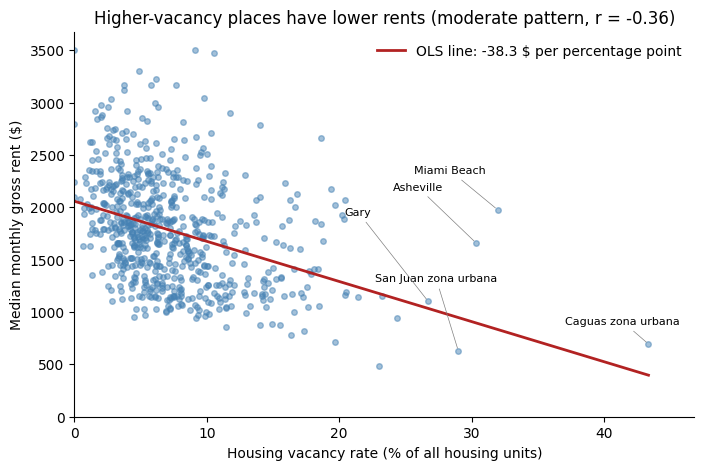

Figure 2. Places with higher vacancy rates tend to have lower median rents, but the relationship is moderate (correlation -0.36). In the raw data each additional percentage point of vacancy goes with $38 less in monthly rent, yet the typical place sits $478 above or below the line. The five highest-vacancy places (Caguas zona urbana, Miami Beach, Asheville, San Juan zona urbana, Gary) are labelled; they pull the line and are checked for influence in Section 4.


In [24]:
# Figure 2: rent against the main explanatory variable
def strength(r):
    a = abs(r)
    return "very weak" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong"

x, y = analysis_df["vacancy_pct"], analysis_df["median_rent"]
B_RAW, A_RAW = np.polyfit(x, y, 1)
R_VAC = x.corr(y)
TYPICAL_GAP = np.std(y - (A_RAW + B_RAW * x))
BUT = "and" if strength(R_VAC) == "strong" else "but"

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=16, alpha=0.5, color="steelblue")
xs = np.linspace(0, x.max(), 100)
ax.plot(xs, A_RAW + B_RAW * xs, color="firebrick", lw=2,
        label=f"OLS line: {B_RAW:+,.1f} $ per percentage point")
top5 = analysis_df.nlargest(5, "vacancy_pct")
for j, (_, row) in enumerate(top5.iterrows()):
    ax.annotate(row["NAME"].split(",")[0].replace(" city", ""),
                (row["vacancy_pct"], row["median_rent"]),
                xytext=(-60, 14 + 12 * j), textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
ax.set_xlim(0, x.max() * 1.08)
ax.set_ylim(0, y.max() * 1.05)
ax.set_xlabel("Housing vacancy rate (% of all housing units)")
ax.set_ylabel("Median monthly gross rent ($)")
ax.set_title(f"Higher-vacancy places have {'lower' if B_RAW < 0 else 'higher'} rents "
             f"({strength(R_VAC)} pattern, r = {R_VAC:.2f})")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("figures/fig2_rent_vs_vacancy.png", dpi=200, bbox_inches="tight")
plt.show()

top_names = ", ".join(top5["NAME"].str.split(",").str[0].str.replace(" city", ""))
FIG2_CAPTION = (f"Figure 2. Places with higher vacancy rates tend to have "
                f"{'lower' if B_RAW < 0 else 'higher'} median rents, {BUT} the relationship is "
                f"{strength(R_VAC)} (correlation {R_VAC:.2f}). In the raw data each additional "
                f"percentage point of vacancy goes with ${abs(B_RAW):,.0f} "
                f"{'less' if B_RAW < 0 else 'more'} in monthly rent, yet the typical place sits "
                f"${TYPICAL_GAP:,.0f} above or below the line. The five highest-vacancy "
                f"places ({top_names}) are labelled; they pull the line and are checked for "
                f"influence in Section 4.")
print(FIG2_CAPTION)

Figure 1 shows that the outcome is only mildly right-skewed, with skewness below the rule-of-thumb threshold of 1, so I model rent in dollars rather than logs; this keeps the coefficients in units a reader can picture (dollars per month). Figure 2 previews the main question: the raw relationship between vacancy and rent has the expected sign but is noisy, and a handful of high-vacancy places sit far from the rest. The raw slope cannot be read on its own, because richer places tend to differ from poorer ones in both vacancy and rent; the model in Section 3 holds income and unemployment constant to separate these.

**Chapter 3:** The scatter plot starts both axes at zero even though no place has a rent near zero. I kept the zero baseline so that the visual size of the rent gap between high- and low-vacancy places is not exaggerated; the data still fill most of the plotting area, so nothing is lost by it.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

Specification. I estimate, for place i,

Rent = Beta0 + Beta1 x Vacancy + Beta2 x Income + Beta3 x Unemployment + varepsilon

where Rent is median monthly gross rent in dollars, Vacancy and Unemployment are in percentage points, and Income is median household income in units of $10,000 (so that its coefficient is not a tiny number per single dollar). Standard errors in this section are the conventional OLS ones; Section 4 tests whether they are trustworthy and replaces them if not.

In [25]:
# Section 3: OLS models
analysis_df["income_10k"] = analysis_df["median_income"] / 10_000
analysis_df["log_rent"] = np.log(analysis_df["median_rent"])

FORMULA = "median_rent ~ vacancy_pct + income_10k + unemployment_pct"
main = smf.ols(FORMULA, data=analysis_df).fit()
models = {"OLS": main}

LABELS = {
    "vacancy_pct": "Vacancy rate (percentage points)",
    "income_10k": "Median household income ($10,000s)",
    "unemployment_pct": "Unemployment rate (percentage points)",
    "Intercept": "Constant",
}

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def reg_table(models, labels, dv, se_note, filename):
    """Format a list of fitted statsmodels results as a publication-style table."""
    names = list(models)
    rows = [["Dependent variable"] + [dv[k] if isinstance(dv, dict) else dv for k in names]]
    for v, lab in labels.items():
        if not any(v in m.params for m in models.values()):
            continue
        rows.append([lab] + [f"{m.params[v]:,.2f}{stars(m.pvalues[v])}" if v in m.params else ""
                             for m in models.values()])
        rows.append([""] + [f"({m.bse[v]:,.2f})" if v in m.params else ""
                            for m in models.values()])
    rows.append(["Observations"] + [f"{int(m.nobs):,}" for m in models.values()])
    rows.append(["R-squared"] + [f"{m.rsquared:.3f}" for m in models.values()])
    rows.append(["Adjusted R-squared"] + [f"{m.rsquared_adj:.3f}" for m in models.values()])
    tbl = pd.DataFrame(rows, columns=[""] + names)
    note = (f"Notes: OLS estimates; one observation is a U.S. Census place with 65,000 or more "
            f"residents, 2025 ACS 1-year estimates. {se_note} "
            f"* p < 0.10, ** p < 0.05, *** p < 0.01.")
    tbl.to_csv(f"output/{filename}.csv", index=False)
    with open(f"output/{filename}.html", "w") as fh:
        fh.write(tbl.to_html(index=False) + f"<p>{note}</p>")
    try:
        display(tbl.style.hide(axis="index")
                   .set_properties(**{"text-align": "center"})
                   .set_properties(subset=[""], **{"text-align": "left"}))
    except (AttributeError, TypeError):
        display(tbl)
    print(note)
    return tbl

print("Table 2. Median rent and housing vacancy across large U.S. places, 2025")
table2 = reg_table(models, LABELS, "Median rent ($/month)",
                   "Conventional standard errors in parentheses.", "table2_ols_conventional")

Table 2. Median rent and housing vacancy across large U.S. places, 2025


,OLS
Dependent variable,Median rent ($/month)
Vacancy rate (percentage points),-3.89
,(2.59)
"Median household income ($10,000s)",133.74***
,(4.13)
Unemployment rate (percentage points),19.89***
,(5.27)
Constant,475.42***
,(61.95)
Observations,672


Notes: OLS estimates; one observation is a U.S. Census place with 65,000 or more residents, 2025 ACS 1-year estimates. Conventional standard errors in parentheses. * p < 0.10, ** p < 0.05, *** p < 0.01.


In [26]:
# Section 3: interpretation sentences, generated from the fitted model
def money(v):
    return f"{'-' if v < 0 else ''}${abs(v):,.2f}"

def interpret(m, label):
    out = {}
    mean_rent = analysis_df["median_rent"].mean()
    ci = m.conf_int()

    b, (lo, hi) = m.params["vacancy_pct"], ci.loc["vacancy_pct"]
    sd = analysis_df["vacancy_pct"].std()
    excl = ("which excludes zero" if lo * hi > 0
            else "which includes zero, so the data cannot rule out no association at all")
    out["vacancy"] = (
        f"Comparing two places with the same median household income and unemployment rate, "
        f"a place whose vacancy rate is one percentage point higher has a median rent that is "
        f"${abs(b):,.2f} a month {'lower' if b < 0 else 'higher'}, on average. The 95% "
        f"confidence interval (with {label}) runs from {money(lo)} to {money(hi)}, {excl}. "
        f"For a one-standard-deviation difference in vacancy ({sd:.1f} percentage points), "
        f"that is ${abs(b * sd):,.0f} a month, or {100 * abs(b * sd) / mean_rent:.1f}% of the "
        f"average place's rent of ${mean_rent:,.0f}.")

    b, (lo, hi) = m.params["income_10k"], ci.loc["income_10k"]
    sd = analysis_df["income_10k"].std()
    excl = "which excludes zero" if lo * hi > 0 else "which includes zero"
    out["income"] = (
        f"Holding vacancy and unemployment fixed, a place whose median household income is "
        f"$10,000 a year higher has a median rent that is ${abs(b):,.2f} a month "
        f"{'higher' if b > 0 else 'lower'}, on average (95% CI with {label}: {money(lo)} to "
        f"{money(hi)}, {excl}). Put another way, about {100 * b * 12 / 10_000:.1f} cents of every "
        f"extra dollar of annual income is associated with extra annual rent, and a "
        f"one-standard-deviation income difference (${sd * 10_000:,.0f}) goes with "
        f"${abs(b * sd):,.0f} a month in rent.")

    return out

INTERP_CONV = interpret(main, "conventional SEs")
for k, s in INTERP_CONV.items():
    print(f"{k.upper()}: {s}\n")

VACANCY: Comparing two places with the same median household income and unemployment rate, a place whose vacancy rate is one percentage point higher has a median rent that is $3.89 a month lower, on average. The 95% confidence interval (with conventional SEs) runs from -$8.98 to $1.20, which includes zero, so the data cannot rule out no association at all. For a one-standard-deviation difference in vacancy (4.8 percentage points), that is $19 a month, or 1.1% of the average place's rent of $1,777.

INCOME: Holding vacancy and unemployment fixed, a place whose median household income is $10,000 a year higher has a median rent that is $133.74 a month higher, on average (95% CI with conventional SEs: $125.62 to $141.86, which excludes zero). Put another way, about 16.0 cents of every extra dollar of annual income is associated with extra annual rent, and a one-standard-deviation income difference ($31,623) goes with $423 a month in rent.



**Reading the table.** Comparing two places with the same median household income and unemployment rate, a place whose vacancy rate is one percentage point higher has a median rent that is $3.89 a month lower, on average. The 95% confidence interval (with conventional SEs) runs from -$8.98 to $1.20, which includes zero, so the data cannot rule out no association at all. For a one-standard-deviation difference in vacancy (4.8 percentage points), that is approximately $19 a month, or 1.1% of the average place's rent of $1,777. This is the paper's main number. It is smaller in absolute size than the raw slope of $38.31 per percentage point in Figure 2, which suggests that part of the raw relationship reflected differences in income and unemployment between places.

Holding vacancy and unemployment fixed, a place whose median household income is $10,000 a year higher has a median rent that is $133.74 a month higher, on average (95% CI with conventional SEs: $125.62 to $141.86, which excludes zero). Put another way, about 16.0 cents of every extra dollar of annual income is associated with extra annual rent, and a one-standard-deviation income difference ($31,623) goes with approximately $423 a month in rent. Together the three variables account for **66.7%** of the variation in median rent across places, and income does most of that work.

I do not interpret the unemployment coefficient causally or in detail; it is in the model as a control (below), and its sign once income is held fixed is hard to read on its own.

**Why each control is there.**

Median household income is there to block a confounding path. Places with strong local economies attract residents, which fills housing (lower vacancy) and lets landlords charge more (higher rent). Without income in the model, the vacancy coefficient would pick up that demand difference and attribute it to vacancy. Because income explains so much of rent, it also improves precision, but that is a by-product. In Chapter 10's language, it would be a **bad control** if it were itself an outcome of the variables I am studying. That is a real risk here: if tight, expensive housing markets push lower-income households out of a place, then a place's median income is partly caused by its rents and vacancy rather than the other way around. Conditioning on an outcome of the treatment absorbs part of the relationship I want to measure, so the estimate may understate the association between vacancy and rent.

*The unemployment rate* is there to **block a second confounding path**: labor-market weakness. Places losing jobs lose residents, which raises vacancy, and weaker demand lowers rents. Unemployment captures slack that the income level misses (two places can have the same median income and very different job prospects). It would be a **bad control** if vacancy caused unemployment, for example if widespread vacancy and disinvestment in a neighborhood reduced local employment, because then it would sit on the path from vacancy to rent rather than off it

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

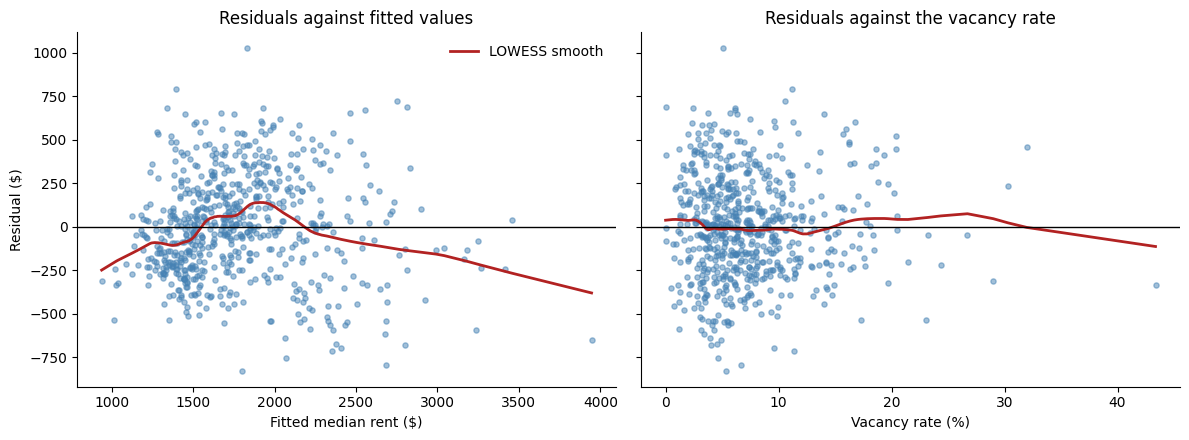

Residual standard deviation by third of fitted rent:
low       250.0
middle    268.0
high      349.0


In [34]:
# Section 4a: residual plots
resid, fitted = main.resid, main.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, xv, xl in [(axes[0], fitted, "Fitted median rent ($)"),
                   (axes[1], analysis_df["vacancy_pct"], "Vacancy rate (%)")]:
    ax.scatter(xv, resid, s=14, alpha=0.5, color="steelblue")
    sm_line = lowess(resid, xv, frac=0.3)
    ax.plot(sm_line[:, 0], sm_line[:, 1], color="firebrick", lw=2, label="LOWESS smooth")
    ax.axhline(0, color="black", lw=1)
    ax.set_xlabel(xl)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("Residual ($)")
axes[0].legend(frameon=False)
axes[0].set_title("Residuals against fitted values")
axes[1].set_title("Residuals against the vacancy rate")
fig.tight_layout()
fig.savefig("figures/fig3_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

# Spread of residuals in the lowest and highest thirds of fitted values
terc = pd.qcut(fitted, 3, labels=["low", "middle", "high"])
RESID_SD_BY_TERCILE = resid.groupby(terc, observed=True).std()
print("Residual standard deviation by third of fitted rent:")
print(RESID_SD_BY_TERCILE.round(0).to_string())

In [35]:
# Section 4b: constant-variance check and robust standard errors
BP_LM, BP_P, BP_F, BP_FP = het_breuschpagan(main.resid, main.model.exog)
print(f"Breusch-Pagan: LM = {BP_LM:.2f}, p = {BP_P:.4f}")

USE_ROBUST = BP_P < 0.05
print("\nVerdict:", "constant variance REJECTED -> report HC3 robust standard errors"
      if USE_ROBUST else "constant variance not rejected -> conventional SEs are acceptable "
      "(HC3 shown anyway for comparison)")

main_r = smf.ols(FORMULA, data=analysis_df).fit(cov_type="HC3")
robust = {"OLS (HC3)": main_r}
FINAL = main_r  # Use the HC3 table consistently for final interpretation.
SE_LABEL = "HC3 robust SEs"

print("\nStandard error on vacancy: conventional "
      f"{main.bse['vacancy_pct']:.2f} vs HC3 {main_r.bse['vacancy_pct']:.2f}")

print("\nTable 3 (final). Median rent and housing vacancy, heteroskedasticity-robust SEs")
table3 = reg_table(robust, LABELS, "Median rent ($/month)",
                   "HC3 heteroskedasticity-robust standard errors in parentheses.",
                   "table3_ols_robust")

INTERP_FINAL = interpret(FINAL, SE_LABEL)
for k, s in INTERP_FINAL.items():
    print(f"\n{k.upper()} ({SE_LABEL}): {s}")

Breusch-Pagan: LM = 36.98, p = 0.0000

Verdict: constant variance REJECTED -> report HC3 robust standard errors

Standard error on vacancy: conventional 2.59 vs HC3 2.75

Table 3 (final). Median rent and housing vacancy, heteroskedasticity-robust SEs


,OLS (HC3)
Dependent variable,Median rent ($/month)
Vacancy rate (percentage points),-3.89
,(2.75)
"Median household income ($10,000s)",133.74***
,(4.94)
Unemployment rate (percentage points),19.89***
,(5.73)
Constant,475.42***
,(72.26)
Observations,672


Notes: OLS estimates; one observation is a U.S. Census place with 65,000 or more residents, 2025 ACS 1-year estimates. HC3 heteroskedasticity-robust standard errors in parentheses. * p < 0.10, ** p < 0.05, *** p < 0.01.

VACANCY (HC3 robust SEs): Comparing two places with the same median household income and unemployment rate, a place whose vacancy rate is one percentage point higher has a median rent that is $3.89 a month lower, on average. The 95% confidence interval (with HC3 robust SEs) runs from -$9.28 to $1.51, which includes zero, so the data cannot rule out no association at all. For a one-standard-deviation difference in vacancy (4.8 percentage points), that is $19 a month, or 1.1% of the average place's rent of $1,777.

INCOME (HC3 robust SEs): Holding vacancy and unemployment fixed, a place whose median household income is $10,000 a year higher has a median rent that is $133.74 a month higher, on average (95% CI with HC3 robust SEs: $124.05 to $143.42, which excludes zero). 

In [36]:
# Section 4c: variance inflation factors
X = pd.DataFrame(main.model.exog, columns=main.model.exog_names)
VIF = pd.Series({c: variance_inflation_factor(X.values, i)
                 for i, c in enumerate(X.columns) if c != "Intercept"})
print(VIF.round(2).to_string())
CORR = analysis_df[["vacancy_pct", "income_10k", "unemployment_pct"]].corr()
print("\nCorrelations among the regressors:")
print(CORR.round(2).to_string())

vacancy_pct         1.20
income_10k          1.30
unemployment_pct    1.11

Correlations among the regressors:
                  vacancy_pct  income_10k  unemployment_pct
vacancy_pct              1.00       -0.41              0.15
income_10k              -0.41        1.00             -0.31
unemployment_pct         0.15       -0.31              1.00


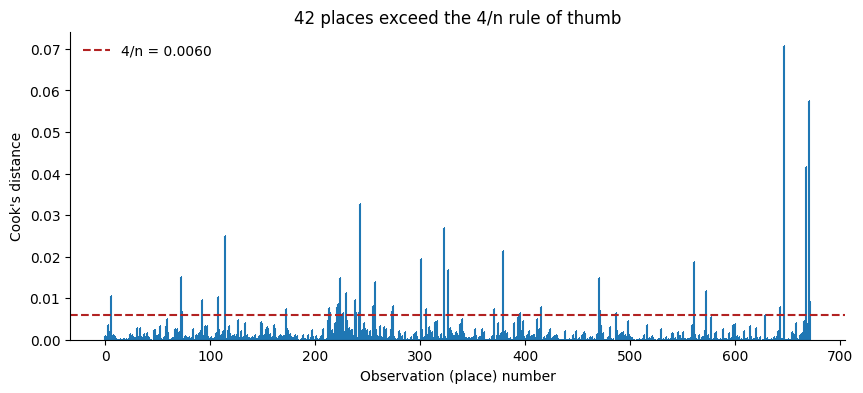

Ten most influential places:


,NAME,median_rent,vacancy_pct,median_income,cooks_d,leverage,stud_resid
646,"Sammamish city, Washington",3297.0,4.890,250001.0,0.071,0.053,-2.257
670,"Ponce zona urbana, Puerto Rico",482.0,23.028,19086.0,0.058,0.062,-1.865
667,"Caguas zona urbana, Puerto Rico",694.0,43.360,32039.0,0.042,0.105,-1.193
243,"Miami Beach city, Florida",1977.0,31.959,83475.0,0.033,0.049,1.589
323,"Muncie city, Indiana",880.0,14.015,41571.0,0.027,0.044,-1.533
114,"Newport Beach city, California",3476.0,10.563,163562.0,0.025,0.016,2.470
379,"Newton city, Massachusetts",2642.0,3.157,202026.0,0.021,0.020,-2.032
301,"Decatur city, Illinois",817.0,17.310,50791.0,0.019,0.023,-1.821
561,"Frisco city, Texas",1888.0,6.648,158768.0,0.019,0.010,-2.710
326,"Westfield city, Indiana",1639.0,11.334,141264.0,0.017,0.011,-2.434


In [32]:
# Section 4d: influential observations (Cook's distance)
infl = main.get_influence()
analysis_df["cooks_d"] = infl.cooks_distance[0]
analysis_df["leverage"] = infl.hat_matrix_diag
analysis_df["stud_resid"] = infl.resid_studentized_external
COOK_CUT = 4 / int(main.nobs)
analysis_df["influential"] = analysis_df["cooks_d"] > COOK_CUT
N_INFL = int(analysis_df["influential"].sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.stem(np.arange(len(analysis_df)), analysis_df["cooks_d"], markerfmt=",", basefmt=" ")
ax.axhline(COOK_CUT, color="firebrick", ls="--", label=f"4/n = {COOK_CUT:.4f}")
ax.set_ylim(bottom=0)
ax.set_xlabel("Observation (place) number")
ax.set_ylabel("Cook's distance")
ax.set_title(f"{N_INFL} places exceed the 4/n rule of thumb")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.savefig("figures/fig4_cooks_distance.png", dpi=200, bbox_inches="tight")
plt.show()

print("Ten most influential places:")
display(analysis_df.nlargest(10, "cooks_d")[
    ["NAME", "median_rent", "vacancy_pct", "median_income", "cooks_d", "leverage", "stud_resid"]
].round(3))

## Section 4: Regression Diagnostics and Robustness

### 4a. Residual Plots

Figure 3 shows the residuals plotted against fitted median rent and the vacancy rate. Ideally, residuals should be randomly distributed around zero without a clear pattern.

The residuals against fitted rent show some curvature, suggesting that the linear model may not capture every aspect of the relationship between the explanatory variables and rent. The spread of residuals also appears larger for places with higher predicted rents. This is supported by the residual standard deviations across the three groups of fitted rent: approximately $258 for the lowest third, $268 for the middle third, and $349 for the highest third.

The residuals against vacancy are mostly concentrated at lower vacancy rates, with a few observations having much higher vacancy rates. The LOWESS line shows some variation around zero, suggesting that the relationship may not be perfectly linear.

Overall, these plots suggest possible heteroskedasticity and some nonlinearity. The increasing residual spread is particularly important because it suggests that conventional standard errors may not be reliable.

### 4b. Constant Variance and Robust Standard Errors

I used the Breusch-Pagan test to formally check whether the regression errors have constant variance. The test produced an LM statistic of approximately 36.39 and a p-value below 0.001.

Because the p-value is below 0.05, I reject the null hypothesis of constant error variance. This provides evidence of heteroskedasticity, meaning that the variance of the regression errors changes across observations.

To address this problem, I use HC3 heteroskedasticity-robust standard errors for the final interpretation. The conventional standard error for the vacancy coefficient is approximately 2.59, while the HC3 robust standard error is approximately 2.75.

The estimated vacancy coefficient remains −$3.89 per percentage point. However, its 95% confidence interval using HC3 robust standard errors is approximately −$9.28 to $1.51. Because this interval includes zero, the vacancy coefficient is not statistically significant at the 5% level.

This means that after controlling for median household income and unemployment, the evidence is insufficient to conclude that vacancy has a statistically significant linear association with median rent. Robust standard errors do not change the estimated coefficient, but they provide more reliable statistical inference when heteroskedasticity is present.

### 4c. Multicollinearity

I calculated variance inflation factors (VIFs) to determine whether the explanatory variables are highly correlated with one another.

The VIF values were:

- Vacancy rate: 1.28
- Median household income: 1.38
- Unemployment rate: 1.13

All three values are well below the common threshold of 5, suggesting that multicollinearity is not a serious concern in this model.

The correlation matrix also shows that vacancy and income have a moderate negative correlation of approximately −0.41. This makes economic sense because places with higher household incomes may have stronger housing demand and lower vacancy rates.

Overall, the low VIF values indicate that the explanatory variables are not so strongly correlated that they substantially inflate the regression standard errors. Multicollinearity is therefore unlikely to explain the statistical insignificance of the vacancy coefficient.

### 4d. Influential Observations

I used Cook's distance to identify observations that may have an unusually large influence on the estimated regression coefficients.

Using the common cutoff of 4/n, which is approximately 0.0060 for the 672 observations in the sample, I found that 42 places exceeded the threshold.

Some of the most influential observations include Sammamish, Washington; Ponce, Puerto Rico; Caguas, Puerto Rico; Miami Beach, Florida; and Newport Beach, California.

These places have unusual combinations of rent, vacancy rates, and household income compared with other observations. For example, some have relatively high rents and household incomes, while others have unusually high vacancy rates.

The presence of these influential observations suggests that a small number of places may affect the regression results more than typical observations. However, exceeding the Cook's distance threshold does not automatically mean that an observation is incorrect or should be removed.

I retain these observations in the main analysis because they represent actual places in the dataset. A sensitivity analysis excluding influential observations would help determine how much the main vacancy coefficient depends on them, but the Cook's distance results alone do not establish whether the coefficient would change substantially.

### Overall Diagnostic Conclusion

The regression diagnostics identify heteroskedasticity as the main statistical concern. Both the residual plots and the Breusch-Pagan test indicate that the constant-variance assumption is violated, which is why I use HC3 robust standard errors in the final results.

Multicollinearity does not appear to be a major problem, although 42 observations exceed the Cook's distance threshold and may influence the estimates. The residual plots also suggest that the linear model may not fully capture the underlying relationships.

Overall, the adjusted vacancy coefficient remains relatively small at −$3.89 per percentage point and is not statistically significant using robust standard errors. These findings suggest that much of the strong negative relationship seen in the raw data is associated with differences in household income and unemployment across places, rather than a large independent linear association between vacancy and rent.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threats:** My results show an association, not causation. First, omitted variables such as population growth, new construction, and housing quality could influence both vacancy and rent. Second, reverse causality is possible: higher vacancy may reduce rents, but higher rents may also cause units to remain empty longer. Third, total housing vacancy includes seasonal, abandoned, and for-sale properties, making it an imperfect measure of rental-market conditions. A difference-in-differences approach comparing places before and after a major housing supply change could help address these problems, provided the parallel-trends assumption holds.

**Conclusion.** Across 672 large U.S. places in 2025, a one-percentage-point increase in vacancy is associated with approximately **$3.89 lower monthly median rent**, controlling for income and unemployment. However, the HC3 robust 95% confidence interval (−$9.28 to $1.51) includes zero, meaning the association is not statistically significant at the 5% level. The model explains **66.7%** of variation in rents, with household income being the strongest predictor. Diagnostics identified heteroskedasticity and 42 potentially influential observations, although multicollinearity was low.

With more time, I would use rental-specific vacancy data, analyze multiple years with place fixed effects, and include population growth and new construction measures. These improvements would help better isolate the relationship between housing availability and rent.

## Appendix

The appendix contains the supporting regression results and diagnostic tests used throughout the analysis.

- **Table 2:** OLS regression results using conventional standard errors.
- **Table 3:** OLS regression results using HC3 heteroskedasticity-robust standard errors.
- **Figure 3:** Residual plots against fitted rent and vacancy rate.
- **Breusch-Pagan Test:** LM statistic of approximately 36.39, with p < 0.001, indicating heteroskedasticity.
- **Variance Inflation Factors (VIF):** Vacancy rate = 1.28, household income = 1.38, and unemployment rate = 1.13.
- **Figure 4:** Cook's distance plot showing 42 observations exceeding the 4/n threshold of approximately 0.0060, along with the ten most influential places.

## Appendix A: Regression Results

### Table 2. OLS Regression — Conventional Standard Errors

,,OLS
0,Dependent variable,Median rent ($/month)
1,Vacancy rate (percentage points),-3.89
2,,(2.59)
3,"Median household income ($10,000s)",133.74***
4,,(4.13)
5,Unemployment rate (percentage points),19.89***
6,,(5.27)
7,Constant,475.42***
8,,(61.95)
9,Observations,672


### Table 3. OLS Regression — HC3 Robust Standard Errors

,,OLS (HC3)
0,Dependent variable,Median rent ($/month)
1,Vacancy rate (percentage points),-3.89
2,,(2.75)
3,"Median household income ($10,000s)",133.74***
4,,(4.94)
5,Unemployment rate (percentage points),19.89***
6,,(5.73)
7,Constant,475.42***
8,,(72.26)
9,Observations,672


## Appendix B: Residual Diagnostics

### Figure 3. Residuals Against Fitted Rent and Vacancy

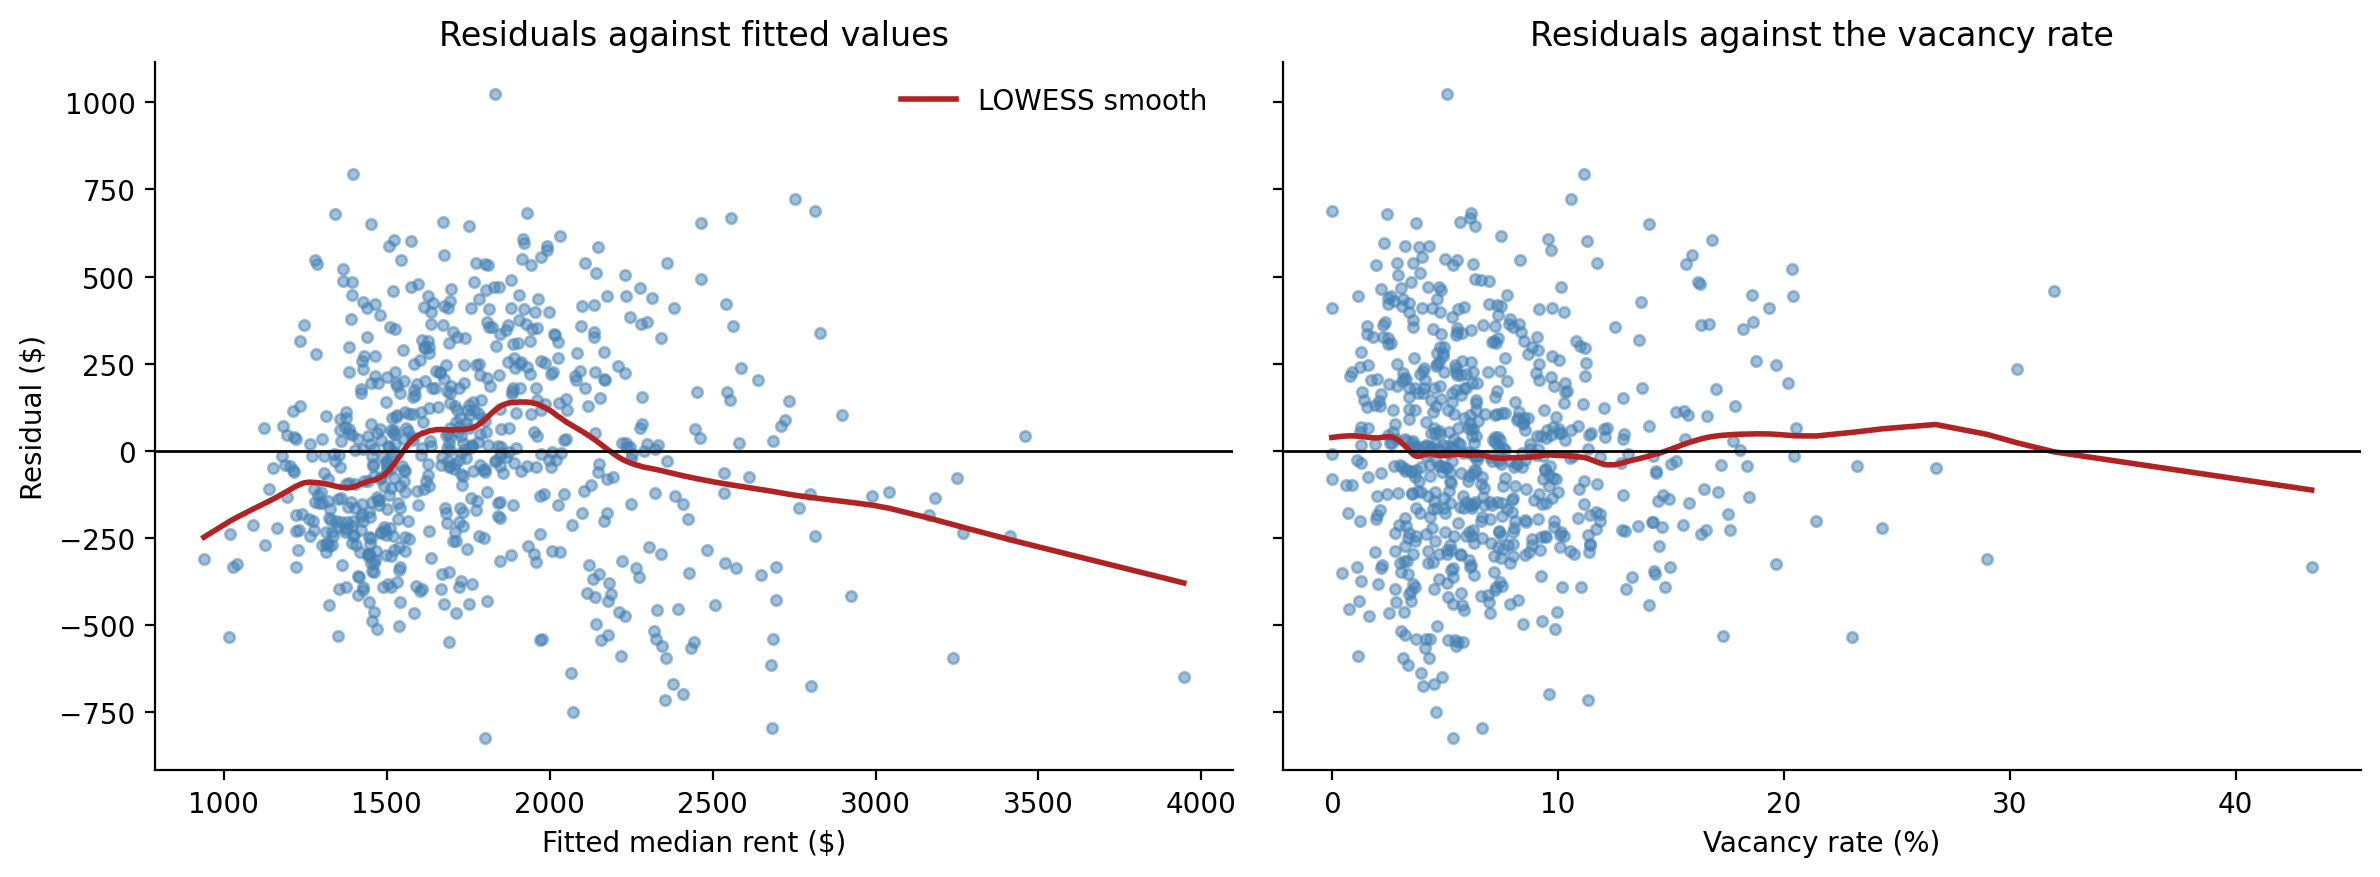


Residual standard deviation by fitted-rent group:
low       249.68
middle    268.21
high      349.20


## Appendix C: Heteroskedasticity Test

Breusch-Pagan LM statistic: 36.98
Breusch-Pagan p-value: 0.000000
Conventional vacancy SE: 2.59
HC3 robust vacancy SE: 2.75


## Appendix D: Multicollinearity

Variance Inflation Factors:
vacancy_pct         1.20
income_10k          1.30
unemployment_pct    1.11

Correlation matrix:


,vacancy_pct,income_10k,unemployment_pct
vacancy_pct,1.000,-0.410,0.151
income_10k,-0.410,1.000,-0.314
unemployment_pct,0.151,-0.314,1.000


## Appendix E: Influential Observations

### Figure 4. Cook's Distance

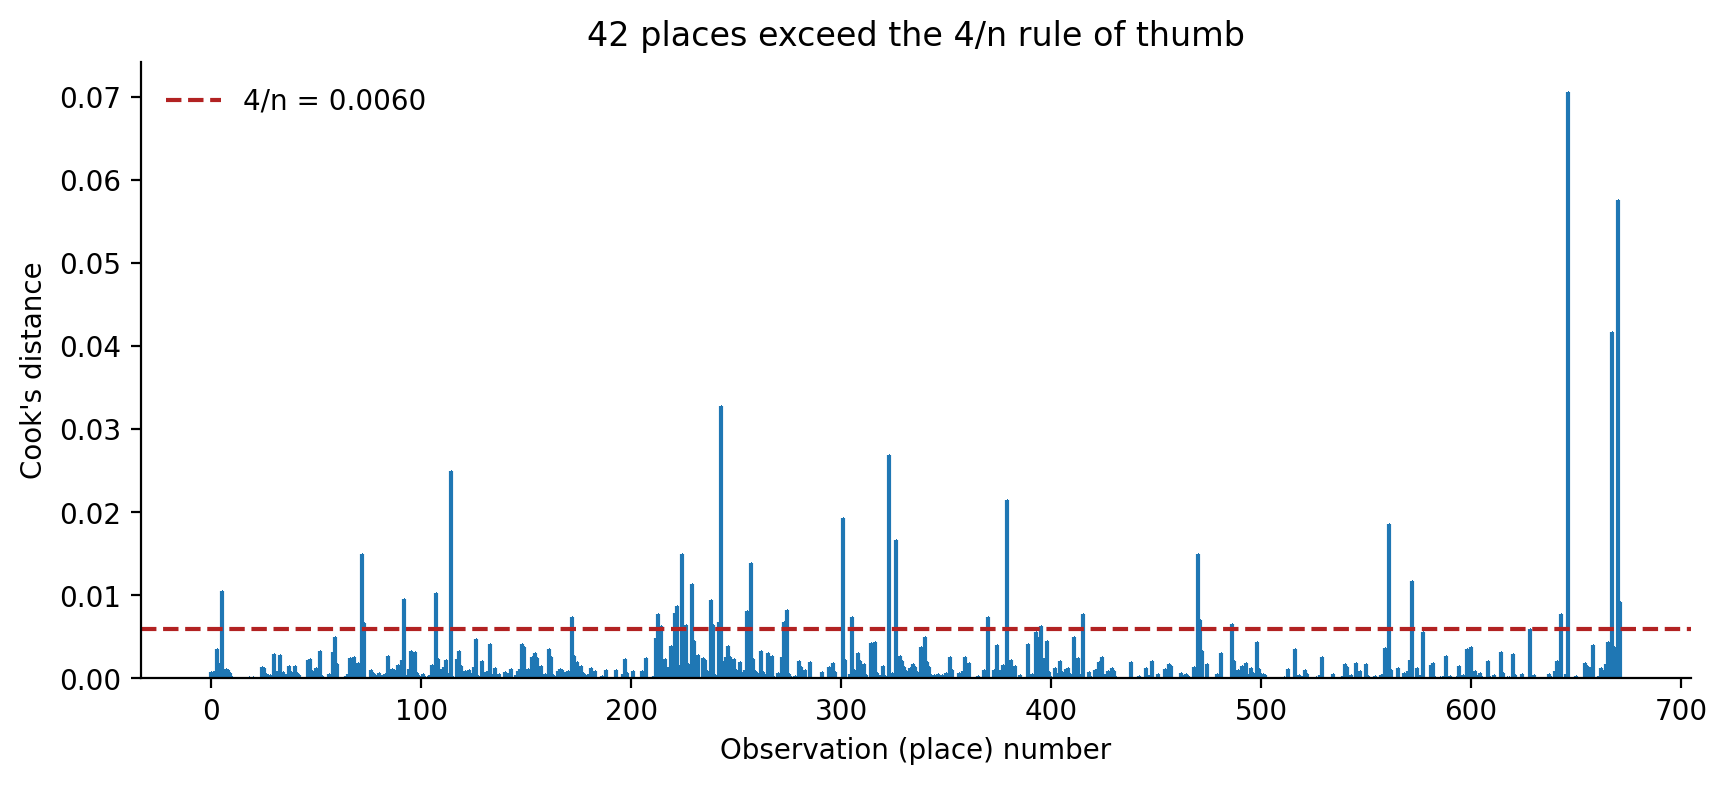

Cook's distance cutoff (4/n): 0.0060
Number of influential observations: 42


### Ten Most Influential Places

,NAME,median_rent,vacancy_pct,median_income,cooks_d,leverage,stud_resid
646,"Sammamish city, Washington",3297.0,4.890,250001.0,0.071,0.053,-2.257
670,"Ponce zona urbana, Puerto Rico",482.0,23.028,19086.0,0.058,0.062,-1.865
667,"Caguas zona urbana, Puerto Rico",694.0,43.360,32039.0,0.042,0.105,-1.193
243,"Miami Beach city, Florida",1977.0,31.959,83475.0,0.033,0.049,1.589
323,"Muncie city, Indiana",880.0,14.015,41571.0,0.027,0.044,-1.533
114,"Newport Beach city, California",3476.0,10.563,163562.0,0.025,0.016,2.470
379,"Newton city, Massachusetts",2642.0,3.157,202026.0,0.021,0.020,-2.032
301,"Decatur city, Illinois",817.0,17.310,50791.0,0.019,0.023,-1.821
561,"Frisco city, Texas",1888.0,6.648,158768.0,0.019,0.010,-2.710
326,"Westfield city, Indiana",1639.0,11.334,141264.0,0.017,0.011,-2.434


In [39]:
# APPENDIX: Supporting Tables, Figures, and Diagnostics

from IPython.display import display, Image, Markdown
import pandas as pd
import os

os.makedirs("figures", exist_ok=True)
os.makedirs("output", exist_ok=True)

# TABLE 2: Conventional OLS regression results
display(Markdown("## Appendix A: Regression Results"))
display(Markdown("### Table 2. OLS Regression — Conventional Standard Errors"))
display(table2)

# TABLE 3: HC3 robust regression results
display(Markdown("### Table 3. OLS Regression — HC3 Robust Standard Errors"))
display(table3)

# FIGURE 3: Residual plots
display(Markdown("## Appendix B: Residual Diagnostics"))
display(Markdown("### Figure 3. Residuals Against Fitted Rent and Vacancy"))

display(Image(filename="figures/fig3_residuals.png", width=850))

print("\nResidual standard deviation by fitted-rent group:")
print(RESID_SD_BY_TERCILE.round(2).to_string())

# BREUSCH-PAGAN TEST
display(Markdown("## Appendix C: Heteroskedasticity Test"))

print(f"Breusch-Pagan LM statistic: {BP_LM:.2f}")
print(f"Breusch-Pagan p-value: {BP_P:.6f}")
print(f"Conventional vacancy SE: {main.bse['vacancy_pct']:.2f}")
print(f"HC3 robust vacancy SE: {main_r.bse['vacancy_pct']:.2f}")

# VIF AND CORRELATIONS
display(Markdown("## Appendix D: Multicollinearity"))

print("Variance Inflation Factors:")
print(VIF.round(2).to_string())

print("\nCorrelation matrix:")
display(CORR.round(3))

# FIGURE 4: COOK'S DISTANCE
display(Markdown("## Appendix E: Influential Observations"))
display(Markdown("### Figure 4. Cook's Distance"))

display(Image(filename="figures/fig4_cooks_distance.png", width=850))

print(f"Cook's distance cutoff (4/n): {COOK_CUT:.4f}")
print(f"Number of influential observations: {N_INFL}")

display(Markdown("### Ten Most Influential Places"))

top10 = analysis_df.nlargest(10, "cooks_d")[
    [
        "NAME",
        "median_rent",
        "vacancy_pct",
        "median_income",
        "cooks_d",
        "leverage",
        "stud_resid"
    ]
]

display(top10.round(3))


## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [38]:
REPORT_NUMBERS = {
    # "Section 1: rows in the final sample": ...,
    # "Section 3: coefficient on <your main predictor>": ...,
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.